<a href="https://colab.research.google.com/github/nandita010/ml-campusproject-colab/blob/main/CampusWalkDataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#ATU Campus Walking Dataset

### Nandita Achsa Reji

## Data Preperation

In [1]:
import pandas as pd

##Load the DataSheet

In [2]:
df = pd.read_csv(
    '/content/drive/MyDrive/Colab Notebooks/CampusWalkDataset_Nandita.csv',
    skiprows = 4
)

### Inspecting the Dataset Datastructure

In [3]:
print("Column names \n")
print(df.dtypes)

print("\nSample Rows\n")
print(df.head())

Column names 

recorder_id                               object
date                                      object
location                                  object
weather                                   object
temperature_c                             object
sound level                               object
foot_traffic                              object
primary_sound_type_urban                  object
other_sound_type_urban                    object
primary_sound_type_nature                 object
other_sound_type_nature                   object
insects_count                            float64
birds_count                              float64
trees_presence                            object
native_or_wild_plant_presence             object
ornnamental_or_planted_plant_presence     object
moss_or_lichen_presence                   object
wellbeing_rating                          object
ease_rating                               object
stress_rating                             object
natur

In [4]:
print(df.sample(5));

    recorder_id        date           location        weather temperature_c  \
991         NaN         NaN                NaN            NaN           NaN   
829         NaN         NaN                NaN            NaN           NaN   
134     R26_028         NaN                NaN            NaN           NaN   
117     R26_024  23/09/2026   L01 MainEntrance  Partly cloudy           17C   
6       R26_002  22/09/2026  L04 PathFrontiHub          Windy            17   

    sound level foot_traffic primary_sound_type_urban other_sound_type_urban  \
991         NaN          NaN                      NaN                    NaN   
829         NaN          NaN                      NaN                    NaN   
134         NaN          NaN                      NaN                    NaN   
117    Moderate     Moderate                  Traffic           Human voices   
6      Moderate          Low                  Traffic                  Other   

    primary_sound_type_nature  ...    wellbe

In [5]:
print(df.describe()) #Looking at information
print(df.info())
print(df.index)

       insects_count  birds_count  Unnamed: 23  Unnamed: 24  Unnamed: 25  \
count     131.000000   131.000000          0.0          0.0          0.0   
mean        2.793893     2.045802          NaN          NaN          NaN   
std         5.167528     2.814421          NaN          NaN          NaN   
min         0.000000     0.000000          NaN          NaN          NaN   
25%         0.000000     0.000000          NaN          NaN          NaN   
50%         1.000000     1.000000          NaN          NaN          NaN   
75%         3.000000     3.000000          NaN          NaN          NaN   
max        31.000000    20.000000          NaN          NaN          NaN   

       Unnamed: 26  
count          0.0  
mean           NaN  
std            NaN  
min            NaN  
25%            NaN  
50%            NaN  
75%            NaN  
max            NaN  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 994 entries, 0 to 993
Data columns (total 27 columns):
 #   Column          

## Importing libraries necessary for the project

In [6]:
#not all are used
#General imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
#K-Means Clustering specific imports
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics import silhouette_score
from sklearn.metrics import homogeneity_score
from sklearn.decomposition import PCA


In [7]:

df= df.dropna(how= 'all')
print(df.head())

  recorder_id        date                        location        weather  \
0     R26_001  22/09/2026                L01 MainEntrance  Partly cloudy   
1     R26_001  22/09/2026                L02 LibraryGreen          Sunny   
2     R26_001  22/09/2026   L06 HedgingBehindSportsCentre  Partly cloudy   
3     R26_001  22/09/2026  L08 AccessRoadNearSportsCentre  Partly cloudy   
4     R26_001  22/09/2026   L06 HedgingBehindSportsCentre          Sunny   

  temperature_c sound level foot_traffic primary_sound_type_urban  \
0            16       Quiet          Low             Human voices   
1            16    Moderate          Low                  Traffic   
2            16       Quiet          Low             Construction   
3            16    Moderate          Low             Human voices   
4            16    Moderate          Low                  Traffic   

  other_sound_type_urban primary_sound_type_nature  ...    wellbeing_rating  \
0                Traffic                      Win

##Deleting all empty rows from 140 onwards

In [8]:
df_first_140 = df.iloc[:140]
columns_to_drop = [col for col in df.columns if 'Unnamed' in col]

df = df.drop(columns=columns_to_drop) #Deletes rows from 140 onwards and drops anything typed "unamed".
print("Columns after dropping Unnamed:")
print(df.columns.tolist())

Columns after dropping Unnamed:
['recorder_id', 'date', 'location', 'weather', 'temperature_c', 'sound level', 'foot_traffic', 'primary_sound_type_urban', 'other_sound_type_urban', 'primary_sound_type_nature', 'other_sound_type_nature', 'insects_count', 'birds_count', 'trees_presence', 'native_or_wild_plant_presence', 'ornnamental_or_planted_plant_presence', 'moss_or_lichen_presence', 'wellbeing_rating', 'ease_rating', 'stress_rating', 'nature_connection_experience_rating', 'most_notable_nature_element', 'other_notes']


In [9]:
print(f"Original shape: {df.shape}")

# Drop rows where critical data like 'date' is missing
df = df.dropna(subset=['date'])

print(f"Cleaned shape (after removing 68 empty rows): {df.shape}")
print("\nRemaining missing values per column:")
print(df.isnull().sum())

Original shape: (199, 23)
Cleaned shape (after removing 68 empty rows): (131, 23)

Remaining missing values per column:
recorder_id                               0
date                                      0
location                                  0
weather                                   0
temperature_c                             0
sound level                               0
foot_traffic                              0
primary_sound_type_urban                  0
other_sound_type_urban                    3
primary_sound_type_nature                 0
other_sound_type_nature                   2
insects_count                             0
birds_count                               0
trees_presence                            4
native_or_wild_plant_presence            10
ornnamental_or_planted_plant_presence    34
moss_or_lichen_presence                  35
wellbeing_rating                          0
ease_rating                               0
stress_rating                             0


## Removing NaN Values
We will drop rows where critical data columns (like `date`) are missing, which removes the trailing empty rows from the dataset.

In [10]:
# Overwrite df directly to drop rows where the 'date' column is NaN
df = df.dropna(subset=['date'])

print(f"New DataFrame shape: {df.shape}")
print("\nUpdated value counts for sound level (NaNs should be gone):")
print(df['sound level'].value_counts(dropna=False))


New DataFrame shape: (131, 23)

Updated value counts for sound level (NaNs should be gone):
sound level
Moderate    58
Quiet       57
Loud        16
Name: count, dtype: int64


#### Missing Data column was deleted therefore the NaN is removed.

### K Means Clustering Algorithm

In [11]:
from sklearn.datasets import load_digits

In [12]:
digits = digits =load_digits()
data = digits.data
target = digits.target

print("Dataset shape:", data.shape)
print("Number of samples:", len(data))
print("Number of features:", data.shape[1])

Dataset shape: (1797, 64)
Number of samples: 1797
Number of features: 64


#### This uses one-hot encoding is used since computers cannot understand words like sunny and weather and when converting this to binary 1 to 0 which allows the computer to understand and display data accordingly

### Encoding Weather

In [13]:

if 'weather' in df.columns:
    print(df['weather'].value_counts(dropna=False))
else:
    print('weather not found')

weather
Sunny            79
Partly cloudy    36
Cloudy            7
sunny             5
Windy             4
Name: count, dtype: int64


In [14]:
# Accessing .str is required for each chained string operation in Pandas and cleaning weather
df['weather'] = df['weather'].str.strip().str.lower()
print(df['weather'].value_counts())

weather
sunny            84
partly cloudy    36
cloudy            7
windy             4
Name: count, dtype: int64


In [15]:
import pandas as pd
import numpy as np

# performing one_hot encoding using pandas to get dummies
weather_encoded = pd.get_dummies(
    df['weather'],
    prefix='weather',
    dtype=int
)

# Concatenate and assign back to df
df = pd.concat([df, weather_encoded], axis=1)

print(df['weather'].value_counts(dropna=False))

print("\n--- Encoded Weather Columns----")
display(df.filter(like='weather_').head())

weather
sunny            84
partly cloudy    36
cloudy            7
windy             4
Name: count, dtype: int64

--- Encoded Weather Columns----


,weather_cloudy,weather_partly cloudy,weather_sunny,weather_windy
0,0,1,0,0
1,0,0,1,0
2,0,1,0,0
3,0,1,0,0
4,0,0,1,0


####Encoding weather means using 1 to see if the row had that specific condition and 0 if it does not have it. One hot encoding is specifically used for weather as there is no natural order and does not make mathematical sense to the computer. Ordinal encoding is used as it has a natural order, for eg: 1, 2, 3 which makes mathematical sense


### Encoding Sound level

In [16]:
if 'sound level' in df.columns:
    print(df['sound level'].value_counts(dropna=False))
else:
    print('sound level not found')

sound level
Moderate    58
Quiet       57
Loud        16
Name: count, dtype: int64


#### The sound level is categorical data so I am encoding by assigning 0, 1 and 2 to Quiet, Moderate and Loud respectively. I am also adding a function that drops repetition of these levels so the output is clean and concise.

In [17]:
#Defining the mapping directory
sound_mapping = {
    'Quiet': 0,
    'Moderate':1,
    'Loud':2,
}
#Create a new numerical column for the encoded values
df['sound_level_encoded'] = df['sound level'].map(sound_mapping)

print("----Mapping Verification----")
print(df[['sound level', 'sound_level_encoded']]
      .drop_duplicates()
      .reset_index(drop= True))

----Mapping Verification----
  sound level  sound_level_encoded
0       Quiet                    0
1    Moderate                    1
2        Loud                    2


### Encoding  bird count

In [18]:
# Keeping the raw bird counts directly as integers (no scaling or binning)
df['birds_count_encoded'] = df['birds_count'].astype(int)

print("--- Raw Bird Count Encoding (No Scaling) ---")
display(df[['birds_count', 'birds_count_encoded']].head(10))

--- Raw Bird Count Encoding (No Scaling) ---


,birds_count,birds_count_encoded
0,1.0,1
1,2.0,2
2,20.0,20
3,2.0,2
4,0.0,0
5,4.0,4
6,2.0,2
7,0.0,0
8,1.0,1
9,2.0,2


#### Simplest way to encode the bird count is to convert it into a number without decimals as encoding is already numbers.

### Well-being, Ease and Stress Data Cleaning and Encoded

In [19]:
# Clean any previously mismatched columns
if 'wellbeing_rating_encoded' in df.columns:
    df = df.drop(columns=['wellbeing_rating_encoded'])

# Find wellbeing, ease, and stress columns
wellbeing_cols = [
    col for col in df.columns
    if any(
        keyword in col.lower()
        for keyword in ['wellbeing', 'ease', 'stress']
    )
]

print("Wellbeing-related columns found:", wellbeing_cols)

# Defining complete ordinal mappings for all unique values observed in the data
wellbeing_map = {
    'Very low wellbeing': 0,
    'Low wellbeing': 1,
    'Neutral': 2,
    'Positive wellbeing': 3,
    'Very positive wellbeing': 4
}

ease_map = {
    'Very uneasy': 0,
    'Slighly uneasy': 1,
    'Neutral': 2,
    'Easy': 3,
    'Vey easy': 4  # keeping dataset typo 'Vey easy'
}

stress_map = {
    'Very stressful': 0,
    'Stressful': 1,
    'Neutral': 2,
    'Mostly calm': 3,
    'Very calm': 4
}

# Apply the mappings to encode the columns cleanly
df['wellbeing_rating_encoded'] = df['wellbeing_rating'].map(wellbeing_map)
df['ease_rating_encoded'] = df['ease_rating'].map(ease_map)
df['stress_rating_encoded'] = df['stress_rating'].map(stress_map)

# Verification of encodings and checking for any unmapped NaNs
for col in ['wellbeing_rating_encoded', 'ease_rating_encoded', 'stress_rating_encoded']:
    print(f"\nValue counts for {col}:")
    print(df[col].value_counts(dropna=False))

print("\n--- Verification Table (First 5 Rows) ---")
display(df[['wellbeing_rating', 'wellbeing_rating_encoded', 'ease_rating', 'ease_rating_encoded', 'stress_rating', 'stress_rating_encoded']].head(5))

Wellbeing-related columns found: ['wellbeing_rating', 'ease_rating', 'stress_rating']

Value counts for wellbeing_rating_encoded:
wellbeing_rating_encoded
3    67
2    37
4    18
1     7
0     2
Name: count, dtype: int64

Value counts for ease_rating_encoded:
ease_rating_encoded
3    56
2    36
4    23
1    15
0     1
Name: count, dtype: int64

Value counts for stress_rating_encoded:
stress_rating_encoded
3    58
2    37
4    29
1     6
0     1
Name: count, dtype: int64

--- Verification Table (First 5 Rows) ---


,wellbeing_rating,wellbeing_rating_encoded,ease_rating,ease_rating_encoded,stress_rating,stress_rating_encoded
0,Positive wellbeing,3,Neutral,2,Stressful,1
1,Positive wellbeing,3,Neutral,2,Neutral,2
2,Positive wellbeing,3,Easy,3,Mostly calm,3
3,Positive wellbeing,3,Neutral,2,Neutral,2
4,Positive wellbeing,3,Easy,3,Mostly calm,3


### Scaling 5 features together

In [20]:
from sklearn.preprocessing import StandardScaler

# 1. Identify all the encoded columns we want to scale
features_to_scale = [
    'weather_cloudy', 'weather_partly cloudy', 'weather_sunny', 'weather_windy',
    'sound_level_encoded',
    'birds_count_encoded',
    'wellbeing_rating_encoded',
    'ease_rating_encoded',
    'stress_rating_encoded'
]

# Ensure only existing columns are grabbed from the DataFrame
existing_features = [col for col in features_to_scale if col in df.columns]

print("Features selected for scaling:", existing_features)

# 2. Extract the dataframe subset
X_unscaled = df[existing_features]

# 3. Initialize and fit the StandardScaler
scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(X_unscaled)

# 4. Convert back to a DataFrame for easier inspection and further clustering or regression
df_scaled = pd.DataFrame(X_scaled_array, columns=existing_features, index=df.index)

# Display the statistics of scaled dataframe to verify mean is ~0 and std is ~1
print("\n--- Scaled Features Summary (Mean should be ~0, Std should be ~1) ---")
display(df_scaled.describe().round(3))

print("\n--- Scaled DataFrame Preview (First 5 rows) ---")
display(df_scaled.head())

# Print each of the scaled column names using a loop
print("\n--- Scaled Column List ---")
for col in df_scaled.columns:
    print(col)

Features selected for scaling: ['weather_cloudy', 'weather_partly cloudy', 'weather_sunny', 'weather_windy', 'sound_level_encoded', 'birds_count_encoded', 'wellbeing_rating_encoded', 'ease_rating_encoded', 'stress_rating_encoded']

--- Scaled Features Summary (Mean should be ~0, Std should be ~1) ---


,weather_cloudy,weather_partly cloudy,weather_sunny,weather_windy,sound_level_encoded,birds_count_encoded,wellbeing_rating_encoded,ease_rating_encoded,stress_rating_encoded
count,131.000,131.000,131.000,131.000,131.000,131.000,131.000,131.000,131.000
mean,0.000,-0.000,0.000,-0.000,-0.000,0.000,0.000,-0.000,-0.000
std,1.004,1.004,1.004,1.004,1.004,1.004,1.004,1.004,1.004
min,-0.238,-0.616,-1.337,-0.177,-1.014,-0.730,-3.271,-2.867,-3.317
25%,-0.238,-0.616,-1.337,-0.177,-1.014,-0.730,-0.850,-0.702,-0.968
50%,-0.238,-0.616,0.748,-0.177,0.462,-0.373,0.360,0.380,0.206
75%,-0.238,1.624,0.748,-0.177,0.462,0.340,0.360,0.380,0.206
max,4.209,1.624,0.748,5.635,1.937,6.404,1.571,1.462,1.381



--- Scaled DataFrame Preview (First 5 rows) ---


,weather_cloudy,weather_partly cloudy,weather_sunny,weather_windy,sound_level_encoded,birds_count_encoded,wellbeing_rating_encoded,ease_rating_encoded,stress_rating_encoded
0,-0.237595,1.624466,-1.336875,-0.177471,-1.013735,-0.373013,0.360401,-0.702216,-2.142830
1,-0.237595,-0.615587,0.748013,-0.177471,0.461812,-0.016336,0.360401,-0.702216,-0.968308
2,-0.237595,1.624466,-1.336875,-0.177471,-1.013735,6.403848,0.360401,0.380023,0.206214
3,-0.237595,1.624466,-1.336875,-0.177471,0.461812,-0.016336,0.360401,-0.702216,-0.968308
4,-0.237595,-0.615587,0.748013,-0.177471,0.461812,-0.729690,0.360401,0.380023,0.206214



--- Scaled Column List ---
weather_cloudy
weather_partly cloudy
weather_sunny
weather_windy
sound_level_encoded
birds_count_encoded
wellbeing_rating_encoded
ease_rating_encoded
stress_rating_encoded


In [21]:
# Show the scaled columns and their first few values cleanly
print("--- Scaled DataFrame Features and Values ---")
for col in df_scaled.columns:
    print(f"\nColumn: {col}")
    print(df_scaled[col].head())

--- Scaled DataFrame Features and Values ---

Column: weather_cloudy
0   -0.237595
1   -0.237595
2   -0.237595
3   -0.237595
4   -0.237595
Name: weather_cloudy, dtype: float64

Column: weather_partly cloudy
0    1.624466
1   -0.615587
2    1.624466
3    1.624466
4   -0.615587
Name: weather_partly cloudy, dtype: float64

Column: weather_sunny
0   -1.336875
1    0.748013
2   -1.336875
3   -1.336875
4    0.748013
Name: weather_sunny, dtype: float64

Column: weather_windy
0   -0.177471
1   -0.177471
2   -0.177471
3   -0.177471
4   -0.177471
Name: weather_windy, dtype: float64

Column: sound_level_encoded
0   -1.013735
1    0.461812
2   -1.013735
3    0.461812
4    0.461812
Name: sound_level_encoded, dtype: float64

Column: birds_count_encoded
0   -0.373013
1   -0.016336
2    6.403848
3   -0.016336
4   -0.729690
Name: birds_count_encoded, dtype: float64

Column: wellbeing_rating_encoded
0    0.360401
1    0.360401
2    0.360401
3    0.360401
4    0.360401
Name: wellbeing_rating_encoded, dty

#### All the features are put together into the feature_to_scale dictionary and scaled. Scaling the data allows all variables to be in the same level mathematically. Mean is used to find the average value which becomes 0 to put data into the center whereas Standard Deviation is 1 to Spread the data by shrinking or expanding data. With the values that are given after encoding and after scaling would not make much sense to the human eyes especially if cloudy weather is defined in decimals, however, it allows the algorithm to work better.


### Visualisation of Clusters of the features

#### PCA Dimensionality Reduction

##### Since humans can only see in 2D or 3D PCA can reduce this data to 2D or 3D. The code below also shows the data shape

In [29]:
import pandas as pd
from sklearn.decomposition import PCA

# 1. Initialize PCA
pca = PCA(n_components=2)

# 2. Fit and transform using raw values (.values) to avoid saving column names
data_projected = pca.fit_transform(df_scaled.values)

# 3. Transform the cluster centers (already a raw array, so no mismatch!)
centroids_projected = pca.transform(kmeans.cluster_centers_)

print("Projected data shape:", data_projected.shape)
print("Projected centroids shape:", centroids_projected.shape)

Projected data shape: (131, 2)
Projected centroids shape: (3, 2)


In [30]:
print(pca.explained_variance_ratio_) #This represents the PC1 and PC2 - X-axis and Y-axis of the plot

[0.28315313 0.19830877]


### Plotting Clusters

Text(0.5, 1.0, 'K-Means Clustering of Campus Walk Dataset')

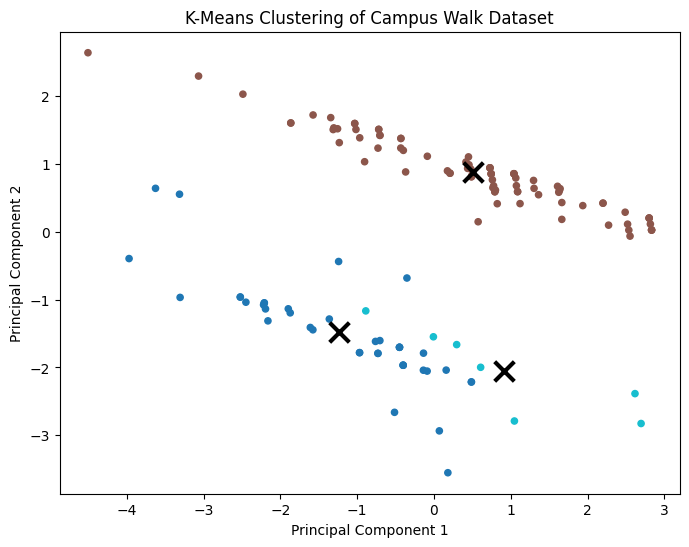

In [38]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6)) # 4:3 ratio

# Using kmeans.labels_ to define colors for the points
plt.scatter(
    data_projected[:, 0],
    data_projected[:, 1],
    c=kmeans.labels_,
    cmap="tab10",
    s=20,
)

plt.scatter(
    centroids_projected[:, 0], #Plotting coordinates X and Y
    centroids_projected[:, 1],
    marker="x",
    c="black",
    s=200,      #color and the size of X
    linewidths=3,
    label="Centroids",
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title(
    "K-Means Clustering of Campus Walk Dataset"
)


###Linear regression

### Reinforcement Learning